# M113 — Tâche 3 : K-means et profils types d'étudiants

**Tâche 3 · Adam** — version initiale (choix de k par silhouette, diagramme de silhouette, heatmap des centroïdes, ACP).
**Compléments · Charaf** — contrôles du contrat `shared/`, application à validation/test, comparaison mesurée des initialisations, K-means réimplémenté avec NumPy, centroïdes en unités d'origine, profils par split, variables illustratives et texte du rapport.

Objectif : appliquer K-means sur les caractéristiques retenues par l'arbre de décision (tâche 1), déterminer le nombre de groupes par le score de silhouette, interpréter les centroïdes, puis comparer les groupes aux étiquettes réelles (`Dropout` / `Enrolled` / `Graduate`) pour voir si des profils à risque apparaissent naturellement.

Exécuter toutes les cellules depuis la racine du dépôt, après la tâche 1. Les entrées viennent uniquement de `shared/`. Les sorties sont écrites dans `results/task3/` et `rapport_partie3.md`. Les objets propres à cette partie portent le préfixe `km_` pour la fusion des notebooks.

In [1]:
from pathlib import Path
from time import perf_counter
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, davies_bouldin_score, f1_score,
                             normalized_mutual_info_score, silhouette_samples, silhouette_score)
from sklearn.preprocessing import StandardScaler

# Avertissement connu de KMeans sous Windows (même filtre que dans le support du cours)
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak on Windows with MKL")

SEED = 42                      # graine commune du groupe
N_INIT = 20                    # nombre d'initialisations par ajustement
K_RANGE = range(2, 11)         # valeurs de k testées
CLASSES = ["Dropout", "Enrolled", "Graduate"]
SPLITS = ["train", "val", "test"]

ROOT = Path.cwd()
SHARED = ROOT / "shared"
RESULTS = ROOT / "results" / "task3"
FIGURES = RESULTS / "figures"
assert SHARED.exists(), "Lancer le notebook depuis la racine du dépôt (dossier shared/ introuvable)."
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)

## 1. Chargement des données partagées et contrôle du contrat

On réutilise exactement les fichiers produits par la tâche 1 : même découpage train / validation / test, mêmes caractéristiques, dans le même ordre. `row_id` sert uniquement d'index pour les jointures. `Target` est gardée dans un tableau séparé et n'entre jamais dans K-means.

Contrôles appliqués (section 2 du contrat commun) : version identique dans `metadata.json` et `selected_features.json`, colonnes identiques à la liste retenue, identifiants uniques et sans chevauchement entre splits, alignement des étiquettes, valeurs finies et présence des trois classes dans chaque split.

In [2]:
km_metadata = json.loads((SHARED / "metadata.json").read_text(encoding="utf-8"))
km_selection = json.loads((SHARED / "selected_features.json").read_text(encoding="utf-8"))
features = km_selection["features"]
assert km_selection["contract_version"] == km_metadata["contract_version"], "Versions du contrat différentes"
assert km_metadata["class_order"] == CLASSES

labels = pd.read_csv(SHARED / "labels.csv", index_col="row_id")
clean = pd.read_csv(SHARED / "data_clean.csv", index_col="row_id")
mapping = pd.read_csv(SHARED / "feature_mapping.csv").set_index("feature")

km_X, km_y, seen = {}, {}, set()
for split in SPLITS:
    X = pd.read_csv(SHARED / f"X_{split}.csv", index_col="row_id")
    assert list(X.columns) == features, f"{split} : colonnes différentes de selected_features.json"
    assert X.index.is_unique and not seen.intersection(X.index), f"{split} : identifiants dupliqués"
    seen.update(X.index)
    assert labels.loc[X.index, "split"].eq(split).all(), f"{split} : affectation incohérente"
    assert np.isfinite(X.to_numpy(dtype=float)).all(), f"{split} : valeurs non finies"
    km_X[split] = X
    km_y[split] = labels.loc[X.index, "Target"]
    assert set(km_y[split]) == set(CLASSES), f"{split} : une classe est absente"
assert seen == set(labels.index)
assert "Target" not in features and "row_id" not in features

print("Version du contrat :", km_metadata["contract_version"], "| caractéristiques :", len(features))
km_class_counts = pd.DataFrame({s: km_y[s].value_counts().reindex(CLASSES) for s in SPLITS}).T
km_class_counts["total"] = km_class_counts.sum(axis=1)
display(km_class_counts)
display(mapping.loc[features, ["source_column", "kind"]])

Version du contrat : 1 | caractéristiques : 11


Target,Dropout,Enrolled,Graduate,total
train,852,476,1325,2653
val,284,158,441,883
test,285,160,443,888


,source_column,kind
feature,,
Curricular units 2nd sem (approved),Curricular units 2nd sem (approved),numeric
Tuition fees up to date,Tuition fees up to date,binary
Curricular units 1st sem (enrolled),Curricular units 1st sem (enrolled),numeric
Curricular units 1st sem (approved),Curricular units 1st sem (approved),numeric
Age at enrollment,Age at enrollment,numeric
Curricular units 2nd sem (evaluations),Curricular units 2nd sem (evaluations),numeric
Curricular units 1st sem (evaluations),Curricular units 1st sem (evaluations),numeric
Curricular units 2nd sem (grade),Curricular units 2nd sem (grade),numeric
Admission grade,Admission grade,numeric


Les 11 colonnes retenues sont toutes quantitatives, sauf `Tuition fees up to date` (binaire 0/1). Aucune colonne one-hot n'a été sélectionnée.

**Limite à garder en tête :** la tâche 1 a choisi ces colonnes avec un arbre entraîné sur les vraies classes. K-means est donc non supervisé, mais il travaille dans un espace **sélectionné de façon supervisée**. Un groupe riche en décrochages traduit une association dans ces données, favorisée par ce choix de variables. Ce n'est pas une découverte entièrement « aveugle ».

## 2. Standardisation

K-means repose sur la distance euclidienne. Sans mise à l'échelle, la note d'admission (≈ 95 à 190) dominerait le nombre d'unités validées (≈ 0 à 20). On centre-réduit chaque colonne avec la moyenne et l'écart-type **appris sur train uniquement**, puis on applique les mêmes paramètres à validation et test. La colonne binaire est aussi centrée-réduite pour lui donner un poids comparable.

In [3]:
km_scaler = StandardScaler().fit(km_X["train"])
km_Z = {split: km_scaler.transform(km_X[split]) for split in SPLITS}
print("Train : moyennes ≈ 0 :", np.allclose(km_Z["train"].mean(axis=0), 0),
      "| écarts-types ≈ 1 :", np.allclose(km_Z["train"].std(axis=0), 1))

Train : moyennes ≈ 0 : True | écarts-types ≈ 1 : True


## 3. Choix du nombre de groupes

Pour un étudiant $i$, $a(i)$ est la distance moyenne aux membres de son groupe et $b(i)$ la distance moyenne au groupe voisin le plus proche. Son coefficient de silhouette vaut

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}} \in [-1, 1].$$

Le score de silhouette est la moyenne des $s(i)$ (à maximiser). On teste k de 2 à 10 sur train, dans l'espace standardisé, avec `init="k-means++"`, `n_init=20` et `random_state=42`. On vérifie aussi que le nombre de groupes réellement formés est compris entre 2 et n − 1 (sinon la silhouette n'est pas définie). L'inertie (méthode du coude) et l'indice de Davies-Bouldin (à minimiser) servent de compléments. **Ce choix n'utilise pas `Target`.**

,k,silhouette,inertie,davies_bouldin,groupes_formes,degenere,plus_petit_groupe,effectifs
0,2,0.4305,20149.1639,1.1307,2,False,503,2150/503
1,3,0.4449,15537.8276,1.0308,3,False,162,2004/487/162
2,4,0.2848,13831.3201,1.5371,4,False,160,1440/630/423/160
3,5,0.2471,12568.2592,1.4368,5,False,158,1240/655/408/192/158
4,6,0.2535,11401.9287,1.3930,6,False,102,1223/645/336/187/160/102
5,7,0.2215,10409.8420,1.2934,7,False,102,950/727/336/206/183/149/102
6,8,0.2240,9655.3736,1.3476,8,False,102,896/747/243/211/172/149/133/102
7,9,0.2282,9023.0552,1.3133,9,False,102,784/483/428/229/192/172/133/130/102
8,10,0.2213,8524.8985,1.3516,10,False,64,831/473/354/227/185/173/130/114/102/64


k retenu (silhouette maximale parmi les valeurs testées) : 3
Deuxième valeur : k = 2, écart de silhouette = 0.014
Solutions dégénérées : 0


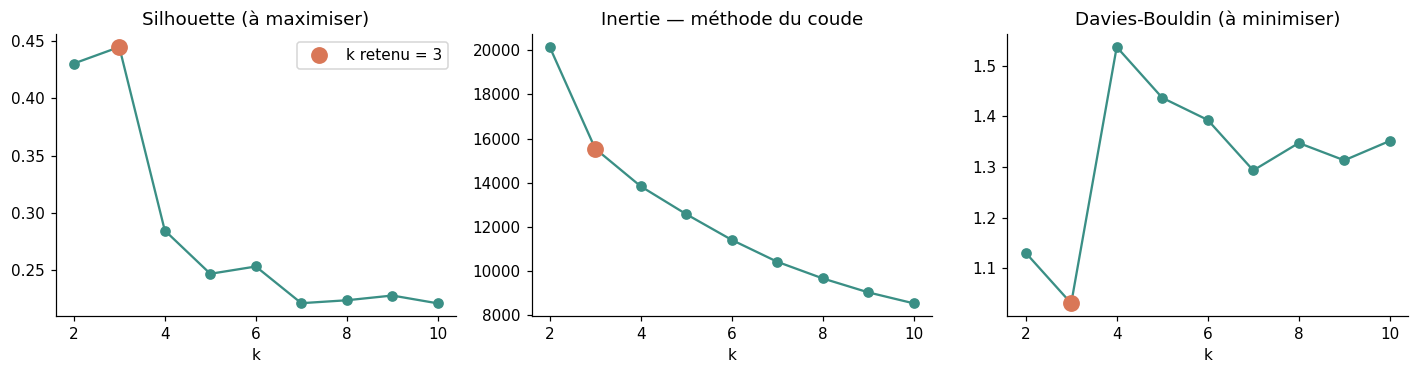

In [4]:
def safe_silhouette(Z, cluster_labels):
    """Silhouette si 2 <= nombre de groupes formés <= n - 1, sinon NaN (cas dégénéré)."""
    formed = len(np.unique(cluster_labels))
    if 2 <= formed <= len(Z) - 1:
        return float(silhouette_score(Z, cluster_labels))
    return float("nan")


rows, km_models = [], {}
for k in K_RANGE:
    model = KMeans(n_clusters=k, init="k-means++", n_init=N_INIT, random_state=SEED).fit(km_Z["train"])
    sizes = np.bincount(model.labels_, minlength=k)
    sil = safe_silhouette(km_Z["train"], model.labels_)
    rows.append({"k": k, "silhouette": sil, "inertie": model.inertia_,
                 "davies_bouldin": davies_bouldin_score(km_Z["train"], model.labels_) if not np.isnan(sil) else np.nan,
                 "groupes_formes": int((sizes > 0).sum()), "degenere": bool(np.isnan(sil)),
                 "plus_petit_groupe": int(sizes.min()), "effectifs": "/".join(map(str, sorted(sizes, reverse=True))),
                 "init": "k-means++", "n_init": N_INIT, "random_state": SEED, "donnees": "train standardisé"})
    km_models[k] = model

km_scores = pd.DataFrame(rows)
km_scores.to_csv(RESULTS / "silhouette_scores.csv", index=False)
display(km_scores.drop(columns=["init", "n_init", "random_state", "donnees"]).round(4))

ranking = km_scores.sort_values("silhouette", ascending=False)
K = int(ranking.iloc[0]["k"])
K_SECOND = int(ranking.iloc[1]["k"])
SIL_GAP = float(ranking.iloc[0]["silhouette"] - ranking.iloc[1]["silhouette"])
print(f"k retenu (silhouette maximale parmi les valeurs testées) : {K}")
print(f"Deuxième valeur : k = {K_SECOND}, écart de silhouette = {SIL_GAP:.3f}")
print("Solutions dégénérées :", int(km_scores["degenere"].sum()))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col, title in zip(axes, ["silhouette", "inertie", "davies_bouldin"],
                          ["Silhouette (à maximiser)", "Inertie — méthode du coude", "Davies-Bouldin (à minimiser)"]):
    ax.plot(km_scores["k"], km_scores[col], "o-", color="#3a8f85")
    ax.plot(K, km_scores.set_index("k").loc[K, col], "o", color="#d97757", ms=10, label=f"k retenu = {K}")
    ax.set(title=title, xlabel="k")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGURES / "choix_k.png", bbox_inches="tight")
plt.show()

### Valeurs proches : comparer les deux meilleures partitions

Quand deux valeurs de k ont des silhouettes proches, on regarde comment les partitions s'emboîtent (tableau croisé des groupes, sans les étiquettes) et leur indice de Rand ajusté (ARI = 1 : partitions identiques, ≈ 0 : sans rapport).

In [5]:
km_nested = pd.crosstab(pd.Series(km_models[K_SECOND].labels_, name=f"groupe (k={K_SECOND})"),
                        pd.Series(km_models[K].labels_, name=f"groupe (k={K})"))
display(km_nested)
print(f"ARI entre k={K_SECOND} et k={K} : {adjusted_rand_score(km_models[K_SECOND].labels_, km_models[K].labels_):.3f}")

groupe (k=3),0,1,2
groupe (k=2),,,
0,0,16,487
1,162,1988,0


ARI entre k=2 et k=3 : 0.776


## 4. Amélioration étudiée : initialisation `random` contre `k-means++`

* **Variante standard** — `init="random"` : les k centres initiaux sont k étudiants tirés au hasard. Deux centres peuvent tomber dans la même zone dense et l'algorithme de Lloyd converge alors vers un minimum local.
* **Amélioration** — `init="k-means++"` (Arthur et Vassilvitskii, 2007) : le premier centre est tiré au hasard, chaque centre suivant est tiré avec une probabilité proportionnelle à $D(x)^2$, la distance au carré au centre déjà choisi le plus proche. Les centres de départ sont donc étalés.

Protocole : k fixé à la valeur retenue, mêmes graines pour les deux variantes (42 à 61, dont 42, 43 et 44), même `n_init`. On mesure inertie, silhouette, nombre d'itérations, temps d'ajustement et ARI par rapport à la solution de référence de la section 3. Deux réglages de `n_init` sont testés :

* `n_init=1` — une seule initialisation, ce qui révèle la sensibilité au point de départ ;
* `n_init=20` — le réglage utilisé en pratique (on garde la meilleure inertie sur 20 départs).

**Règle de choix, fixée avant de lire les résultats (critères internes uniquement) :** avec `n_init=1`, retenir la variante qui atteint le plus souvent la meilleure inertie connue, puis la plus faible inertie moyenne, puis le moins d'itérations.

L'avantage théorique de k-means++ grandit avec le nombre de groupes, car il devient plus probable qu'un tirage uniforme place deux centres dans la même zone. On répète donc la même mesure à k = 8, à titre de contrôle complémentaire. La règle de choix ne porte que sur le k retenu.

In [6]:
INIT_SEEDS = list(range(42, 62))
K_CONTROL = 8
km_reference = km_models[K].labels_

rows = []
for k_cmp in [K, K_CONTROL]:
    for n_init in [1, N_INIT]:
        for init in ["random", "k-means++"]:
            for seed in INIT_SEEDS:
                started = perf_counter()
                model = KMeans(n_clusters=k_cmp, init=init, n_init=n_init, random_state=seed).fit(km_Z["train"])
                elapsed = perf_counter() - started
                rows.append({"k": k_cmp, "variante": init, "n_init": n_init, "graine": seed,
                             "inertie": model.inertia_, "silhouette": safe_silhouette(km_Z["train"], model.labels_),
                             "iterations": int(model.n_iter_), "temps_s": elapsed,
                             "ari_vs_reference": adjusted_rand_score(km_models[k_cmp].labels_, model.labels_)})
km_init = pd.DataFrame(rows)
best_by_k = km_init.groupby("k")["inertie"].transform("min")
km_init["atteint_meilleure_inertie"] = km_init["inertie"] <= best_by_k * (1 + 1e-6)
km_init.to_csv(RESULTS / "initialization_comparison.csv", index=False)
best_inertia = km_init.loc[km_init["k"] == K, "inertie"].min()

km_init_summary = km_init.groupby(["k", "n_init", "variante"]).agg(
    inertie_moy=("inertie", "mean"), inertie_std=("inertie", "std"), inertie_max=("inertie", "max"),
    silhouette_moy=("silhouette", "mean"), silhouette_min=("silhouette", "min"),
    iterations_moy=("iterations", "mean"), temps_moy_ms=("temps_s", lambda s: 1000 * s.mean()),
    ari_moy=("ari_vs_reference", "mean"), ari_min=("ari_vs_reference", "min"),
    part_meilleure_inertie=("atteint_meilleure_inertie", "mean"))
display(km_init_summary.round(4))

single = km_init_summary.loc[(K, 1)].sort_values(["part_meilleure_inertie", "inertie_moy", "iterations_moy"],
                                            ascending=[False, True, True])
INIT_CHOICE = single.index[0]
print("Meilleure inertie connue :", round(best_inertia, 3))
print("Variante retenue par la règle :", INIT_CHOICE)

inertie_moy  inertie_std  inertie_max  silhouette_moy  silhouette_min  iterations_moy  temps_moy_ms  ari_moy  ari_min  \
k n_init variante                                                                                                                           
3 1      k-means++   15844.2864     944.5729   18755.8490          0.4373          0.3436           15.50        4.4668   0.9671   0.6389   
         random      15683.3853     650.9539   18448.9821          0.4398          0.3436           15.25        3.9997   0.9819   0.6389   
  20     k-means++   15537.8276       0.0000   15537.8276          0.4449          0.4449           15.85       43.4882   1.0000   1.0000   
         random      15537.8276       0.0000   15537.8276          0.4449          0.4449           15.60       47.2547   1.0000   1.0000   
8 1      k-means++   10028.4403     318.9657   10656.6640          0.2254          0.1887           19.05        5.8277   0.6380   0.3414   
         random      10060.0444     284.6767   10652.3961          0.2122          0.1765           22.20        5.1785   0.5235   0.3414   
  20     k-means++    9661.1568      24.4836    9764.8560          0.2267          0.2183           21.30       87.8418   0.9109   0.4628   
         random       9699.7407      54.9303    9765.5284          0.2239          0.2175           29.30       75.7194   0.7422   0.4614   

                    part_meilleure_inertie  
k n_init variante                           
3 1      k-means++                    0.90  
         random                       0.95  
  20     k-means++                    1.00  
         random                       1.00  
8 1      k-means++                    0.00  
         random                       0.00  
  20     k-means++                    0.05  
         random                       0.00

Meilleure inertie connue : 15537.828
Variante retenue par la règle : random


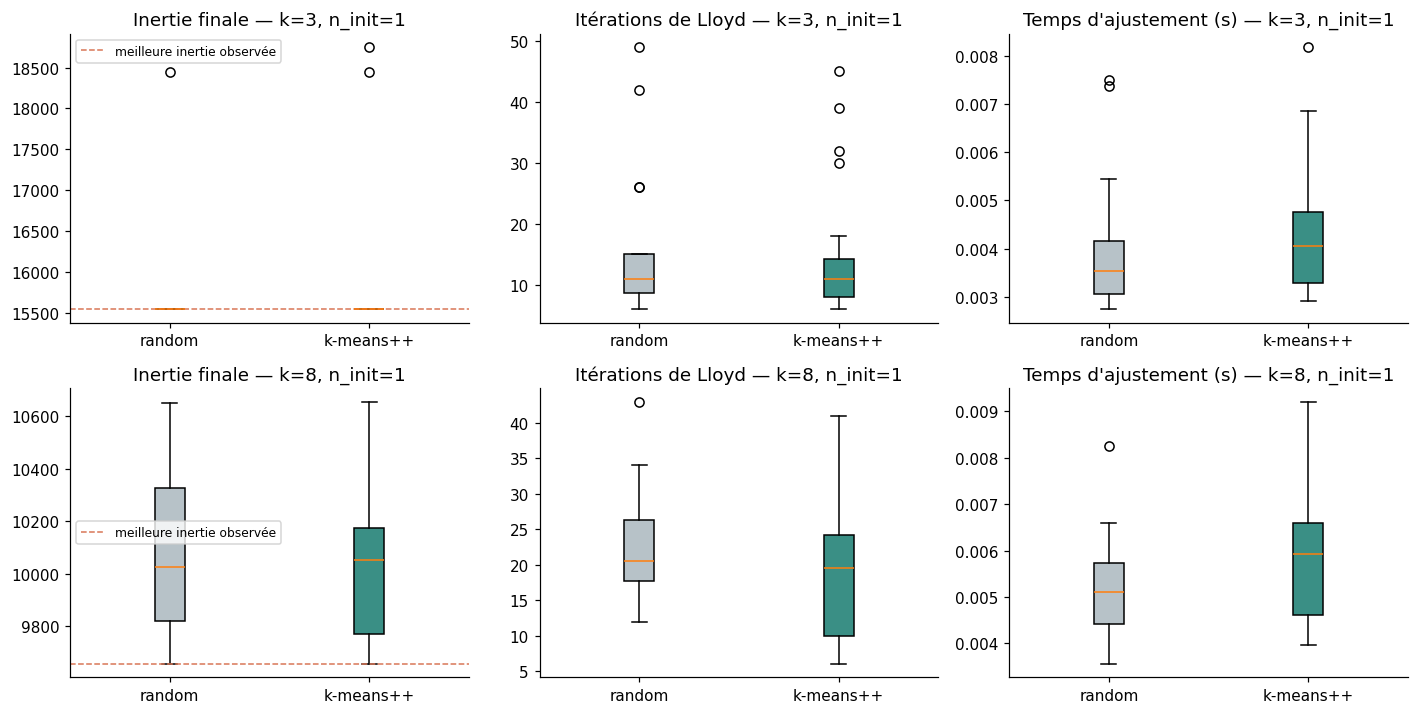

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6))
variants = ["random", "k-means++"]
colors = ["#b7c2c8", "#3a8f85"]
for row_axes, k_cmp in zip(axes, [K, K_CONTROL]):
    single_runs = km_init[(km_init["n_init"] == 1) & (km_init["k"] == k_cmp)]
    for ax, col, title in zip(row_axes, ["inertie", "iterations", "temps_s"],
                              ["Inertie finale", "Itérations de Lloyd", "Temps d'ajustement (s)"]):
        data = [single_runs.loc[single_runs["variante"] == v, col] for v in variants]
        box = ax.boxplot(data, patch_artist=True)
        ax.set_xticks([1, 2], variants)
        for patch, color in zip(box["boxes"], colors):
            patch.set_facecolor(color)
        ax.set_title(f"{title} — k={k_cmp}, n_init=1")
    row_axes[0].axhline(single_runs["inertie"].min(), ls="--", color="#d97757", lw=1, label="meilleure inertie observée")
    row_axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "comparaison_initialisation.png", bbox_inches="tight")
plt.show()

## 5. Code personnalisé : K-means réimplémenté avec NumPy

Pour vérifier notre compréhension de l'algorithme et ne pas dépendre d'une boîte noire, on réimplémente K-means avec NumPy :

1. **Initialisation** `random` ou `k-means++` (tirage proportionnel à $D(x)^2$).
2. **Affectation** : chaque étudiant rejoint le centre le plus proche (distance euclidienne au carré).
3. **Mise à jour** : chaque centre devient la moyenne de ses membres. Un groupe vide est réinitialisé sur le point le plus éloigné de son centre.
4. Répéter 2–3 jusqu'à stabilité des centres. Avec `n_init` départs, garder la solution d'inertie minimale $\sum_i \lVert x_i - \mu_{c(i)} \rVert^2$.

On teste d'abord la fonction sur trois nuages de points bien séparés, puis on compare sa solution à celle de scikit-learn sur nos données.

In [8]:
def squared_distances(X, centers):
    """Matrice n x k des distances euclidiennes au carré."""
    return ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)


def init_centers(X, k, init, rng):
    if init == "random":
        return X[rng.choice(len(X), size=k, replace=False)].copy()
    centers = [X[rng.integers(len(X))]]
    d2 = ((X - centers[0]) ** 2).sum(axis=1)
    for _ in range(1, k):
        probs = d2 / d2.sum() if d2.sum() > 0 else np.full(len(X), 1 / len(X))
        new_center = X[rng.choice(len(X), p=probs)]
        centers.append(new_center)
        d2 = np.minimum(d2, ((X - new_center) ** 2).sum(axis=1))
    return np.array(centers)


def kmeans_numpy(X, k, init="k-means++", n_init=10, max_iter=300, tol=1e-8, seed=42):
    """K-means (Lloyd) avec NumPy. Retourne centres, étiquettes, inertie et nombre d'itérations."""
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        centers = init_centers(X, k, init, rng)
        for iteration in range(1, max_iter + 1):
            d2 = squared_distances(X, centers)
            assignment = d2.argmin(axis=1)
            new_centers = centers.copy()
            for j in range(k):
                members = assignment == j
                if members.any():
                    new_centers[j] = X[members].mean(axis=0)
                else:  # groupe vide : repartir du point le plus mal représenté
                    new_centers[j] = X[d2.min(axis=1).argmax()]
            shift = ((new_centers - centers) ** 2).sum()
            centers = new_centers
            if shift <= tol:
                break
        d2 = squared_distances(X, centers)
        assignment = d2.argmin(axis=1)
        inertia = float(d2[np.arange(len(X)), assignment].sum())
        if best is None or inertia < best["inertia"]:
            best = {"centers": centers, "labels": assignment, "inertia": inertia, "n_iter": iteration}
    return best


# Vérification sur trois nuages séparés : la partition doit être retrouvée exactement
toy_rng = np.random.default_rng(0)
toy_truth = np.repeat([0, 1, 2], 50)
toy_X = np.vstack([toy_rng.normal(center, 0.3, size=(50, 2)) for center in [(0, 0), (5, 5), (0, 6)]])
toy = kmeans_numpy(toy_X, 3, seed=0)
assert adjusted_rand_score(toy_truth, toy["labels"]) == 1.0
assert np.bincount(toy["labels"]).tolist() == [50, 50, 50]
print("Test sur données synthétiques réussi.")

started = perf_counter()
km_custom = kmeans_numpy(km_Z["train"], K, init="k-means++", n_init=N_INIT, seed=SEED)
custom_time = perf_counter() - started
sk_inertia = km_models[K].inertia_
print(f"Inertie NumPy       : {km_custom['inertia']:.3f}  ({custom_time:.2f} s)")
print(f"Inertie scikit-learn: {sk_inertia:.3f}")
print(f"Écart relatif       : {(km_custom['inertia'] - sk_inertia) / sk_inertia:+.2e}")
print(f"ARI entre les deux partitions : {adjusted_rand_score(km_models[K].labels_, km_custom['labels']):.4f}")

Test sur données synthétiques réussi.
Inertie NumPy       : 15537.828  (0.14 s)
Inertie scikit-learn: 15537.828
Écart relatif       : +0.00e+00
ARI entre les deux partitions : 1.0000


## 6. Modèle final et application à validation/test

Le modèle final est ajusté sur train avec k retenu, l'initialisation choisie à la section 4, `n_init=20` et `random_state=42`. Les numéros de groupes produits par K-means sont arbitraires. Pour une lecture stable, on renumérote les groupes selon le centroïde de `Curricular units 2nd sem (approved)`, du plus faible au plus fort (critère interne, sans `Target`).

Validation et test sont ensuite affectés au centroïde le plus proche avec `predict`, sans réajustement. Une silhouette proche de celle de train indique que la structure se retrouve sur des étudiants non vus.

In [9]:
ORDER_FEATURE = "Curricular units 2nd sem (approved)"
km_final = KMeans(n_clusters=K, init=INIT_CHOICE, n_init=N_INIT, random_state=SEED).fit(km_Z["train"])
order = np.argsort(km_final.cluster_centers_[:, features.index(ORDER_FEATURE)])
relabel = np.empty(K, dtype=int)
relabel[order] = np.arange(K)
km_centers = km_final.cluster_centers_[order]           # centroïdes standardisés, nouvel ordre
km_clusters = {split: relabel[km_final.predict(km_Z[split])] for split in SPLITS}
assert np.array_equal(km_clusters["train"], relabel[km_final.labels_])
print("ARI avec la solution de la section 3 :", round(adjusted_rand_score(km_reference, km_clusters["train"]), 4))

rows = []
for split in SPLITS:
    sizes = np.bincount(km_clusters[split], minlength=K)
    sil = safe_silhouette(km_Z[split], km_clusters[split])
    rows.append({"split": split, "n": len(km_clusters[split]), "silhouette": sil,
                 "remarque": "" if not np.isnan(sil) else "silhouette non définie (un seul groupe)",
                 **{f"groupe_{c}": int(sizes[c]) for c in range(K)}})
km_split_quality = pd.DataFrame(rows).set_index("split")
display(km_split_quality.round(4))

ARI avec la solution de la section 3 : 1.0


,n,silhouette,remarque,groupe_0,groupe_1,groupe_2
split,,,,,,
train,2653,0.4449,,487,2004,162
val,883,0.4582,,162,673,48
test,888,0.4447,,187,664,37


### Diagramme de silhouette (train)

Chaque barre horizontale est un étudiant. Un groupe dont les barres sont longues et régulières est compact et bien séparé. Des valeurs négatives indiquent des étudiants plus proches d'un autre groupe que du leur.

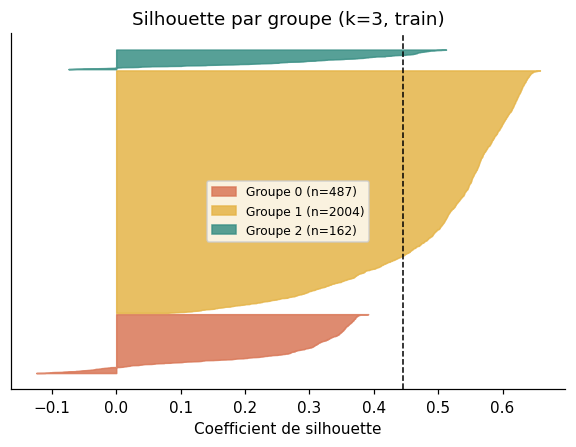

,silhouette_moyenne,part_negative_pct
0,0.251,10.267
1,0.504,0.000
2,0.298,8.025


In [10]:
sil_samples = silhouette_samples(km_Z["train"], km_clusters["train"])
fig, ax = plt.subplots(figsize=(6.5, 4.2))
y_lower = 10
palette = ["#d97757", "#e5b448", "#3a8f85", "#5b7db1", "#9b6fb0", "#7f7f7f"]
for c in range(K):
    vals = np.sort(sil_samples[km_clusters["train"] == c])
    ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, alpha=0.85,
                     color=palette[c % len(palette)], label=f"Groupe {c} (n={len(vals)})")
    y_lower += len(vals) + 10
ax.axvline(sil_samples.mean(), color="k", ls="--", lw=1)
ax.set(title=f"Silhouette par groupe (k={K}, train)", xlabel="Coefficient de silhouette", yticks=[])
ax.legend(fontsize=8)
plt.savefig(FIGURES / "silhouette_clusters.png", bbox_inches="tight")
plt.show()

km_sil_by_group = pd.DataFrame({"silhouette_moyenne": pd.Series(sil_samples).groupby(km_clusters["train"]).mean(),
                                "part_negative_pct": pd.Series(sil_samples < 0).groupby(km_clusters["train"]).mean() * 100})
display(km_sil_by_group.round(3))

## 7. Interprétation des centroïdes

Deux lectures complémentaires :

* **Centroïdes standardisés** (heatmap) : 0 = moyenne de train, ±1 = un écart-type. On voit quelles variables distinguent chaque groupe.
* **Centroïdes en unités d'origine** : on applique l'inverse du scaler (`inverse_transform`). Comme un centroïde K-means est la moyenne de ses membres et que la standardisation est affine, il est égal à la moyenne du groupe dans les unités d'origine (vérifié ci-dessous avec `data_clean.csv`). Pour la colonne binaire `Tuition fees up to date`, la valeur est une **proportion** d'étudiants à jour de leurs frais.

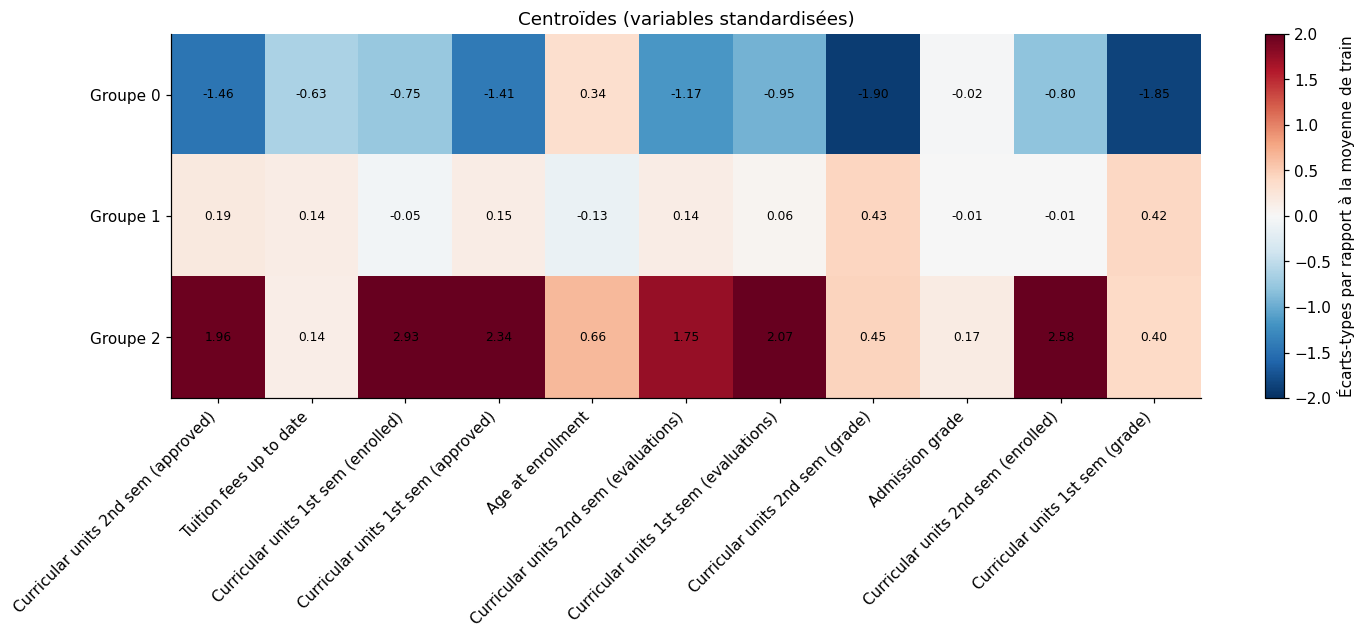

,Groupe 0,Groupe 1,Groupe 2,moyenne_train
Curricular units 2nd sem (approved),0.06,5.09,10.48,4.50
Tuition fees up to date,0.67,0.92,0.92,0.87
Curricular units 1st sem (enrolled),4.40,6.20,13.85,6.33
Curricular units 1st sem (approved),0.34,5.25,12.13,4.77
Age at enrollment,25.95,22.36,28.36,23.39
Curricular units 2nd sem (evaluations),3.48,8.70,15.11,8.14
Curricular units 1st sem (evaluations),4.39,8.64,17.12,8.38
Curricular units 2nd sem (grade),0.49,12.50,12.63,10.30
Admission grade,126.88,127.04,129.63,127.17
Curricular units 2nd sem (enrolled),4.48,6.26,12.08,6.29


In [11]:
group_names = [f"Groupe {c}" for c in range(K)]
fig, ax = plt.subplots(figsize=(1.1 * len(features) + 3, 0.7 * K + 2.2))
im = ax.imshow(km_centers, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(features)), features, rotation=45, ha="right")
ax.set_yticks(range(K), group_names)
for i in range(K):
    for j in range(len(features)):
        ax.text(j, i, f"{km_centers[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Écarts-types par rapport à la moyenne de train")
ax.set_title("Centroïdes (variables standardisées)")
plt.savefig(FIGURES / "centroides_heatmap.png", bbox_inches="tight")
plt.show()

km_centroids_original = pd.DataFrame(km_scaler.inverse_transform(km_centers), columns=features)
km_centroids_original.insert(0, "effectif_train", np.bincount(km_clusters["train"], minlength=K))
km_centroids_original.insert(0, "cluster", range(K))

# Vérification : centroïde dé-standardisé = moyenne du groupe dans data_clean.csv
group_means = clean.loc[km_X["train"].index, features].groupby(km_clusters["train"]).mean()
assert np.allclose(group_means.to_numpy(), km_centroids_original[features].to_numpy(), atol=1e-6)

train_means = km_X["train"].mean().rename("moyenne_train")
display(pd.concat([km_centroids_original.set_index("cluster")[features].T.set_axis(group_names, axis=1),
                   train_means], axis=1).round(2))

### Variables illustratives (non utilisées par K-means)

Pour décrire les profils au-delà des 11 colonnes, on calcule dans chaque groupe quelques variables d'origine **qui n'ont pas servi au clustering** : boursiers, débiteurs, genre, déplacés, cours du soir et filières les plus fréquentes. Codes d'après le dictionnaire UCI : `Gender` 1 = homme, `Debtor` / `Scholarship holder` / `Displaced` 1 = oui, `Daytime/evening attendance` 1 = journée.

In [12]:
COURSE_NAMES = {
    33: "Biofuel Production Technologies", 171: "Animation and Multimedia Design",
    8014: "Social Service (evening)", 9003: "Agronomy", 9070: "Communication Design",
    9085: "Veterinary Nursing", 9119: "Informatics Engineering", 9130: "Equinculture",
    9147: "Management", 9238: "Social Service", 9254: "Tourism", 9500: "Nursing",
    9556: "Oral Hygiene", 9670: "Advertising and Marketing Management",
    9773: "Journalism and Communication", 9853: "Basic Education", 9991: "Management (evening)",
}
assert set(clean["Course"].unique()) <= set(COURSE_NAMES)

train_clean = clean.loc[km_X["train"].index]
illustrative = {"Scholarship holder": "boursiers_pct", "Debtor": "debiteurs_pct", "Gender": "hommes_pct",
                "Displaced": "deplaces_pct", "Daytime/evening attendance": "cours_jour_pct"}
km_illustrative = train_clean[list(illustrative)].groupby(km_clusters["train"]).mean() * 100
km_illustrative.loc["Ensemble train"] = train_clean[list(illustrative)].mean() * 100
km_illustrative = km_illustrative.rename(columns=illustrative)
km_illustrative.index = group_names + ["Ensemble train"]
display(km_illustrative.round(1))

course_rows = []
for c in range(K):
    shares = train_clean.loc[km_clusters["train"] == c, "Course"].value_counts(normalize=True).head(3)
    course_rows.append({"groupe": f"Groupe {c}",
                        "filieres_principales": "; ".join(f"{COURSE_NAMES[code]} ({100 * p:.0f} %)" for code, p in shares.items())})
km_courses = pd.DataFrame(course_rows).set_index("groupe")
display(km_courses)

,boursiers_pct,debiteurs_pct,hommes_pct,deplaces_pct,cours_jour_pct
Groupe 0,10.3,19.5,51.1,46.4,85.0
Groupe 1,28.0,10.0,30.5,58.3,90.5
Groupe 2,14.8,15.4,36.4,40.1,74.1
Ensemble train,24.0,12.1,34.6,55.0,88.5


,filieres_principales
groupe,
Groupe 0,Animation and Multimedia Design (21 %); Management (evening) (9 %); Management (8 %)
Groupe 1,Nursing (20 %); Social Service (9 %); Journalism and Communication (8 %)
Groupe 2,Agronomy (17 %); Animation and Multimedia Design (14 %); Management (evening) (14 %)


## 8. Répartition des étiquettes réelles dans chaque groupe

Le modèle étant fixé, on joint maintenant les vraies étiquettes par `row_id`. Pour chaque split, on calcule les effectifs et les pourcentages de `Dropout`, `Enrolled` et `Graduate` dans chaque groupe (les pourcentages sont calculés sur l'effectif du groupe et totalisent 100 %). On compare le taux de décrochage de chaque groupe au taux du **même** split avec le rapport `ratio_dropout` = taux du groupe / taux du split. Un rapport supérieur à 1 signale une sur-représentation des décrocheurs.

Les étiquettes de validation et de test servent seulement à décrire le résultat final ; elles n'interviennent ni dans le choix de k ni dans l'ajustement.

In [13]:
rows = []
for split in SPLITS:
    y = km_y[split]
    split_dropout_pct = 100 * (y == "Dropout").mean()
    counts = pd.crosstab(km_clusters[split], y).reindex(index=range(K), columns=CLASSES, fill_value=0)
    for c in range(K):
        n = int(counts.loc[c].sum())
        row = {"split": split, "cluster": c, "effectif": n, "part_du_split_pct": 100 * n / len(y)}
        row.update({f"n_{cls}": int(counts.loc[c, cls]) for cls in CLASSES})
        row.update({f"pct_{cls}": 100 * counts.loc[c, cls] / n if n else np.nan for cls in CLASSES})
        row["taux_dropout_split_pct"] = split_dropout_pct
        row["ratio_dropout"] = row["pct_Dropout"] / split_dropout_pct if n else np.nan
        rows.append(row)
km_profiles = pd.DataFrame(rows)
pct_cols = [f"pct_{cls}" for cls in CLASSES]
assert np.allclose(km_profiles[pct_cols].sum(axis=1), 100)
km_profiles.to_csv(RESULTS / "cluster_profiles.csv", index=False)
display(km_profiles.round(1))

rows = []
for split in SPLITS:
    y, cl = km_y[split], km_clusters[split]
    counts = pd.crosstab(cl, y)
    rows.append({"split": split, "purete": counts.max(axis=1).sum() / len(y),
                 "reference_classe_majoritaire": y.value_counts(normalize=True).max(),
                 "ARI": adjusted_rand_score(y, cl), "NMI": normalized_mutual_info_score(y, cl)})
km_agreement = pd.DataFrame(rows).set_index("split")
display(km_agreement.round(3))

,split,cluster,effectif,part_du_split_pct,n_Dropout,n_Enrolled,n_Graduate,pct_Dropout,pct_Enrolled,pct_Graduate,taux_dropout_split_pct,ratio_dropout
0,train,0,487,18.4,403,39,45,82.8,8.0,9.2,32.1,2.6
1,train,1,2004,75.5,413,415,1176,20.6,20.7,58.7,32.1,0.6
2,train,2,162,6.1,36,22,104,22.2,13.6,64.2,32.1,0.7
3,val,0,162,18.3,132,17,13,81.5,10.5,8.0,32.2,2.5
4,val,1,673,76.2,144,135,394,21.4,20.1,58.5,32.2,0.7
5,val,2,48,5.4,8,6,34,16.7,12.5,70.8,32.2,0.5
6,test,0,187,21.1,156,13,18,83.4,7.0,9.6,32.1,2.6
7,test,1,664,74.8,123,143,398,18.5,21.5,59.9,32.1,0.6
8,test,2,37,4.2,6,4,27,16.2,10.8,73.0,32.1,0.5


,purete,reference_classe_majoritaire,ARI,NMI
split,,,,
train,0.634,0.499,0.139,0.153
val,0.634,0.499,0.135,0.152
test,0.654,0.499,0.174,0.188


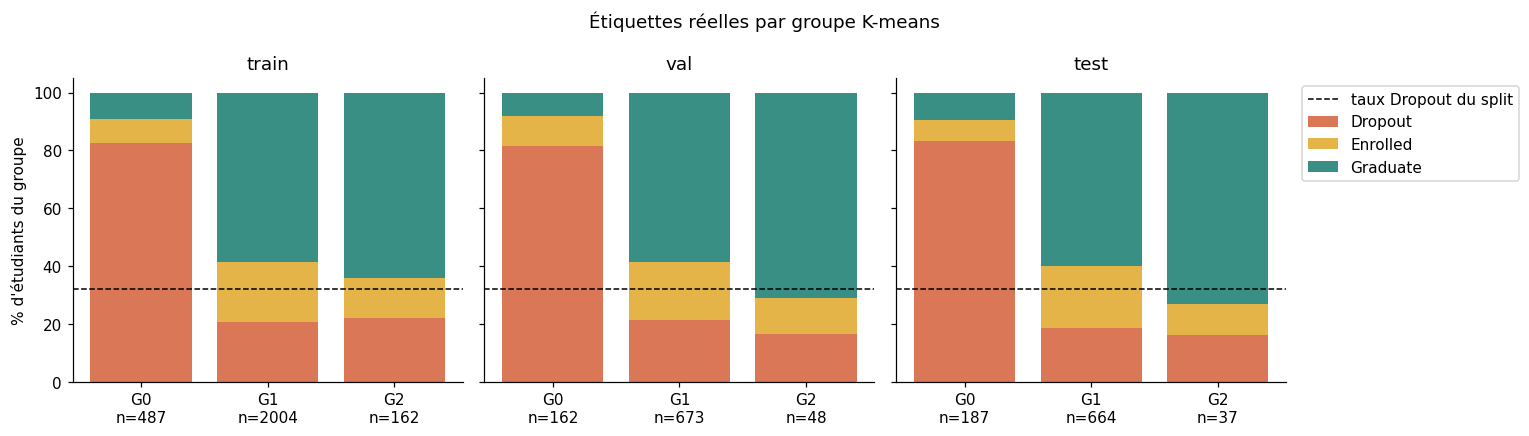

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
class_colors = ["#d97757", "#e5b448", "#3a8f85"]
for ax, split in zip(axes, SPLITS):
    part = km_profiles[km_profiles["split"] == split].set_index("cluster")
    bottom = np.zeros(K)
    for cls, color in zip(CLASSES, class_colors):
        ax.bar(range(K), part[f"pct_{cls}"], bottom=bottom, color=color, label=cls)
        bottom += part[f"pct_{cls}"].to_numpy()
    ax.axhline(part["taux_dropout_split_pct"].iloc[0], color="k", ls="--", lw=1, label="taux Dropout du split")
    ax.set_xticks(range(K), [f"G{c}\nn={n}" for c, n in zip(part.index, part["effectif"])])
    ax.set_title(split)
axes[0].set_ylabel("% d'étudiants du groupe")
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.suptitle("Étiquettes réelles par groupe K-means")
plt.tight_layout()
plt.savefig(FIGURES / "labels_par_cluster.png", bbox_inches="tight")
plt.show()

### Cas particulier : étudiants sans aucune unité inscrite

Sur l'ACP (section 10), une bande verticale d'étudiants du groupe 0 apparaît à l'extrême gauche, et beaucoup d'entre eux sont diplômés. Ce sont des étudiants avec **0 unité inscrite aux deux semestres** (et aucune unité créditée). Leurs valeurs académiques nulles ne décrivent pas un échec mais une absence d'information sur le cursus suivi. On mesure leur poids dans le groupe 0 pour ne pas sur-interpréter ce groupe. Ils restent dans le clustering, car le contrat commun ne les exclut pas.

In [15]:
UNITS_1, UNITS_2 = "Curricular units 1st sem (enrolled)", "Curricular units 2nd sem (enrolled)"
rows = []
for split in SPLITS:
    X, cl, y = km_X[split], km_clusters[split], km_y[split]
    in_g0 = cl == 0
    no_units = (X[UNITS_1].eq(0) & X[UNITS_2].eq(0)).to_numpy()
    rest = in_g0 & ~no_units
    rows.append({"split": split, "groupe_0": int(in_g0.sum()), "sans_unite_inscrite": int((in_g0 & no_units).sum()),
                 "dont_Graduate": int((in_g0 & no_units & (y == "Graduate").to_numpy()).sum()),
                 "sans_unite_hors_groupe_0": int((~in_g0 & no_units).sum()),
                 "pct_Dropout_groupe_0": 100 * (y[in_g0] == "Dropout").mean(),
                 "pct_Dropout_groupe_0_sans_ces_cas": 100 * (y[rest] == "Dropout").mean()})
km_no_units = pd.DataFrame(rows).set_index("split")
display(km_no_units.round(1))

,groupe_0,sans_unite_inscrite,dont_Graduate,sans_unite_hors_groupe_0,pct_Dropout_groupe_0,pct_Dropout_groupe_0_sans_ces_cas
split,,,,,,
train,487,101,44,0,82.8,93.3
val,162,38,13,0,81.5,92.7
test,187,41,18,0,83.4,95.2


## 9. Lecture supervisée a posteriori (fonction `map_labels` du cours)

Comme dans le support du cours (*KMeans — groupement des caractères*), on associe à chaque groupe la classe majoritaire de ses membres sur train, puis on applique ce mapping aux groupes prédits pour validation et test. Ce n'est pas un classifieur optimisé : cela mesure seulement à quel point les groupes « naturels » recouvrent les classes. Le résultat ne sert pas à choisir k.

In [16]:
def map_labels(km_labels, y):
    """Reprise de la fonction du cours : classe majoritaire de chaque groupe."""
    mapping_ = {}
    for i in np.unique(km_labels):
        mapping_[i] = pd.Series(y)[km_labels == i].value_counts().reindex(CLASSES).idxmax()
    return mapping_


km_map = map_labels(km_clusters["train"], km_y["train"].to_numpy())
print("Groupe -> classe majoritaire :", km_map)
rows = []
for split in SPLITS:
    pred = pd.Series(km_clusters[split]).map(km_map).to_numpy()
    rows.append({"split": split, "accuracy": (pred == km_y[split].to_numpy()).mean(),
                 "f1_macro": f1_score(km_y[split], pred, labels=CLASSES, average="macro", zero_division=0),
                 "classes_jamais_predites": ", ".join(sorted(set(CLASSES) - set(pred))) or "aucune"})
km_mapping_scores = pd.DataFrame(rows).set_index("split")
display(km_mapping_scores.round(3))

task2_metrics = ROOT / "results" / "task2" / "test_metrics.csv"
if task2_metrics.exists():
    print("Pour comparaison, F1 macro test de la tâche 2 :")
    display(pd.read_csv(task2_metrics)[["model", "macro_f1"]].round(3))

Groupe -> classe majoritaire : {np.int64(0): 'Dropout', np.int64(1): 'Graduate', np.int64(2): 'Graduate'}


,accuracy,f1_macro,classes_jamais_predites
split,,,
train,0.634,0.445,Enrolled
val,0.634,0.443,Enrolled
test,0.654,0.468,Enrolled


Pour comparaison, F1 macro test de la tâche 2 :


,model,macro_f1
0,Logistic regression,0.707
1,Linear SVM,0.696
2,RBF SVM,0.646


## 10. Visualisation en 2D (ACP)

L'ACP sert uniquement à la visualisation : elle est apprise sur train standardisé, alors que K-means a été ajusté dans l'espace complet des 11 caractéristiques. Deux groupes qui se chevauchent sur ce plan peuvent être séparés dans les dimensions non représentées.

Variance expliquée : [0.482 0.153] | total : 0.635


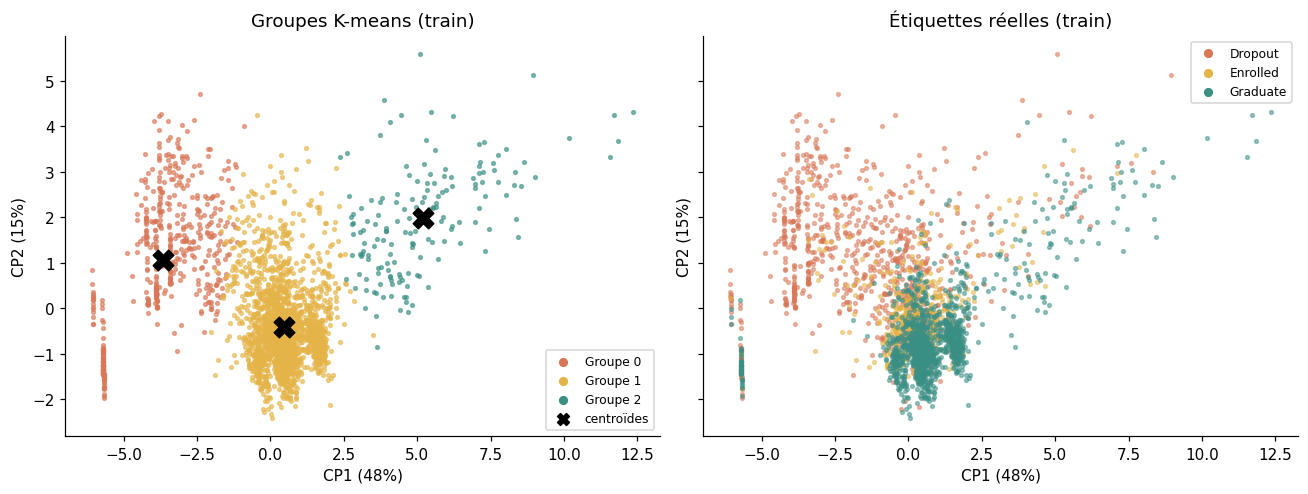

In [17]:
km_pca = PCA(n_components=2, random_state=SEED).fit(km_Z["train"])
P = km_pca.transform(km_Z["train"])
C = km_pca.transform(km_centers)
explained = km_pca.explained_variance_ratio_
print("Variance expliquée :", explained.round(3), "| total :", round(explained.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
for c in range(K):
    mask = km_clusters["train"] == c
    axes[0].scatter(P[mask, 0], P[mask, 1], s=6, alpha=0.6, color=palette[c % len(palette)], label=f"Groupe {c}")
axes[0].scatter(C[:, 0], C[:, 1], marker="X", s=180, color="k", label="centroïdes")
axes[0].set_title("Groupes K-means (train)")
for cls, color in zip(CLASSES, class_colors):
    mask = km_y["train"].to_numpy() == cls
    axes[1].scatter(P[mask, 0], P[mask, 1], s=6, alpha=0.5, color=color, label=cls)
axes[1].set_title("Étiquettes réelles (train)")
for ax in axes:
    ax.set(xlabel=f"CP1 ({explained[0]:.0%})", ylabel=f"CP2 ({explained[1]:.0%})")
    legend = ax.legend(fontsize=8)
    for handle in legend.legend_handles:
        handle.set_sizes([60 if handle.get_label() == "centroïdes" else 25])
        handle.set_alpha(1)
plt.tight_layout()
plt.savefig(FIGURES / "pca_clusters.png", bbox_inches="tight")
plt.show()

## 11. Sauvegarde des résultats

| Fichier | Contenu |
| --- | --- |
| `silhouette_scores.csv` | k, silhouette, inertie, Davies-Bouldin, effectifs, contrôle de dégénérescence et paramètres |
| `initialization_comparison.csv` | variante, `n_init`, graine, inertie, silhouette, itérations, temps, ARI |
| `cluster_assignments.csv` | `row_id`, `split`, `cluster`, `Target` pour les 4 424 étudiants |
| `centroids_original.csv` | centroïdes dans les unités d'origine (avant standardisation) |
| `cluster_profiles.csv` | split, groupe, effectif, effectifs et pourcentages par classe, rapport au taux de décrochage |
| `kmeans_summary.json` | résumé des choix et des mesures principales |

Les sorties de cette partie restent dans `results/task3/`. Le dossier `shared/` n'est pas modifié.

In [18]:
km_assignments = pd.concat([
    pd.DataFrame({"split": split, "cluster": km_clusters[split], "Target": km_y[split]}, index=km_X[split].index)
    for split in SPLITS]).sort_index()
km_assignments.index.name = "row_id"
assert km_assignments.index.is_unique and len(km_assignments) == len(labels)
km_assignments.to_csv(RESULTS / "cluster_assignments.csv")
km_centroids_original.to_csv(RESULTS / "centroids_original.csv", index=False)

km_summary = {
    "contract_version": km_metadata["contract_version"], "features": features, "k": K,
    "k_range": [min(K_RANGE), max(K_RANGE)], "second_best_k": K_SECOND, "silhouette_gap": SIL_GAP,
    "init": INIT_CHOICE, "n_init": N_INIT, "random_state": SEED, "cluster_order_feature": ORDER_FEATURE,
    "silhouette": {split: km_split_quality.loc[split, "silhouette"] for split in SPLITS},
    "cluster_sizes": {split: np.bincount(km_clusters[split], minlength=K).tolist() for split in SPLITS},
    "agreement_with_target": km_agreement.round(4).to_dict(orient="index"),
    "numpy_kmeans_inertia": km_custom["inertia"], "sklearn_inertia": float(km_models[K].inertia_),
}
(RESULTS / "kmeans_summary.json").write_text(json.dumps(km_summary, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("Fichiers écrits :", sorted(p.name for p in RESULTS.glob("*.*")))

Fichiers écrits : ['centroids_original.csv', 'cluster_assignments.csv', 'cluster_profiles.csv', 'initialization_comparison.csv', 'kmeans_summary.json', 'silhouette_scores.csv']


## 12. Synthèse

* La silhouette retient **k = 3**, de peu devant k = 2. Les deux partitions s'emboîtent : k = 3 garde le groupe en échec et isole en plus un petit groupe à forte charge de cours.
* **Un profil à risque se dégage naturellement** : le groupe 0 (environ un étudiant sur cinq) n'a presque aucune unité validée dès le premier semestre. Il est composé à plus de 80 % de décrocheurs, soit plus de deux fois le taux moyen, et ce constat se retrouve sur validation et test. Une partie du groupe n'a aucune unité inscrite (zéros non informatifs, souvent des diplômés) ; sans ces cas, la part de décrocheurs dépasse 90 %.
* La classe `Enrolled` ne forme pas de groupe : elle se mêle surtout au grand groupe « parcours régulier ». K-means décrit des profils mais ne remplace pas les classifieurs de la tâche 2.
* L'initialisation k-means++ n'apporte rien à k = 3 sur ces données (les deux variantes convergent vers la même partition avec `n_init=20`). Son avantage apparaît au contrôle à k = 8.
* Limites : espace de variables choisi de façon supervisée, variables du second semestre (lecture rétrospective), et groupes de tailles très inégales.

La cellule suivante génère `rapport_partie3.md` à partir des résultats de cette exécution. Des assertions vérifient que les affirmations qualitatives du texte restent vraies si les données changent.

In [19]:
def markdown_table(frame, floatfmt="{:.3f}"):
    def fmt(value):
        if isinstance(value, (float, np.floating)):
            return "—" if np.isnan(value) else floatfmt.format(value)
        return str(value)
    header = "| " + " | ".join(map(str, frame.columns)) + " |"
    divider = "| " + " | ".join(["---"] * len(frame.columns)) + " |"
    rows = ["| " + " | ".join(fmt(v) for v in row) + " |" for row in frame.itertuples(index=False, name=None)]
    return "\n".join([header, divider] + rows)


# --- Garde-fous : le texte ci-dessous décrit 3 groupes avec ces propriétés ---
assert K == 3, "Le texte d'interprétation suppose k = 3 : le réviser."
prof = km_profiles.set_index(["split", "cluster"])
assert all(prof.loc[(s, 0), "ratio_dropout"] > 2 for s in SPLITS), "Le groupe 0 n'est plus un profil à risque"
assert all(prof.loc[(s, 2), "pct_Graduate"] > prof.loc[(s, 1), "pct_Graduate"] for s in SPLITS)
enrolled_in_1 = prof.loc[("train", 1), "n_Enrolled"] / km_y["train"].eq("Enrolled").sum()
assert enrolled_in_1 > 0.5, "Enrolled n'est plus majoritairement dans le groupe 1"
s3, s8 = km_init_summary.loc[(K, N_INIT)], km_init_summary.loc[(K_CONTROL, N_INIT)]
assert (s3["ari_min"] == 1).all(), "À k = 3, les deux initialisations ne convergent plus vers la même partition"
kpp_better_k8 = (s8.loc["k-means++", "inertie_moy"] < s8.loc["random", "inertie_moy"]
                 and s8.loc["k-means++", "ari_moy"] > s8.loc["random", "ari_moy"])
assert kpp_better_k8, "Le constat sur k = 8 a changé : réviser le texte."

nu = km_no_units
assert (nu["pct_Dropout_groupe_0_sans_ces_cas"] > nu["pct_Dropout_groupe_0"]).all()
co = km_centroids_original.set_index("cluster")
ill = km_illustrative
tr = km_X["train"].mean()
sc = km_scores.set_index("k")
s1 = km_init_summary.loc[(K, 1)]
n_split = {s: len(km_y[s]) for s in SPLITS}

k_table = km_scores[["k", "silhouette", "inertie", "davies_bouldin", "effectifs"]].copy()
k_table["inertie"] = k_table["inertie"].map(lambda v: f"{v:.0f}")
init_table = km_init_summary.reset_index()[["k", "n_init", "variante", "inertie_moy", "inertie_std",
                                            "silhouette_moy", "iterations_moy", "temps_moy_ms", "ari_moy",
                                            "part_meilleure_inertie"]].copy()
for col in ["inertie_moy", "inertie_std"]:
    init_table[col] = init_table[col].map(lambda v: f"{v:.0f}")
for col in ["iterations_moy", "temps_moy_ms"]:
    init_table[col] = init_table[col].map(lambda v: f"{v:.1f}")
init_table["part_meilleure_inertie"] = init_table["part_meilleure_inertie"].map(lambda v: f"{100 * v:.0f} %")
quality_table = km_split_quality.reset_index().drop(columns="remarque")
centroid_table = co[features].T.set_axis(group_names, axis=1)
centroid_table["Moyenne train"] = tr
centroid_table = centroid_table.reset_index().rename(columns={"index": "Variable"})
centroid_table = pd.concat([pd.DataFrame([{"Variable": "Effectif (train)", **{g: f"{n}" for g, n in zip(group_names, co["effectif_train"])},
                                           "Moyenne train": f"{n_split['train']}"}]), centroid_table.astype(object)])
centroid_table = centroid_table.map(lambda v: f"{v:.2f}" if isinstance(v, float) else v)
ill_table = ill.reset_index().rename(columns={"index": "Groupe"})
profile_table = km_profiles[["split", "cluster", "effectif", "pct_Dropout", "pct_Enrolled", "pct_Graduate", "ratio_dropout"]].copy()
profile_table.columns = ["Split", "Groupe", "Effectif", "% Dropout", "% Enrolled", "% Graduate", "Ratio Dropout"]
for col in ["% Dropout", "% Enrolled", "% Graduate"]:
    profile_table[col] = profile_table[col].map(lambda v: f"{v:.1f}")
profile_table["Ratio Dropout"] = profile_table["Ratio Dropout"].map(lambda v: f"{v:.2f}")
agreement_table = km_agreement.reset_index()
mapping_table = km_mapping_scores.reset_index()
task2_line = ""
if task2_metrics.exists():
    best_task2 = pd.read_csv(task2_metrics).sort_values("macro_f1", ascending=False).iloc[0]
    task2_line = (f" À titre de comparaison, le meilleur modèle supervisé de la tâche 2 ({best_task2['model']}) "
                  f"atteint {best_task2['macro_f1']:.3f} sur le même test.")

report = f"""# M113 — Contribution de la tâche 3 : K-means et profils d'étudiants

*Notebook `03_kmeans.ipynb` : version initiale d'Adam, compléments de Charaf. Tous les chiffres proviennent de l'exécution du notebook sur le dossier `shared/` version {km_metadata['contract_version']}.*

## Objectif

Cette partie cherche si un algorithme non supervisé, K-means, fait apparaître des profils types d'étudiants à partir des {len(features)} caractéristiques retenues par l'arbre de la tâche 1. On vérifie ensuite si certains profils concentrent les décrochages, sans avoir donné les étiquettes à l'algorithme.

## Données et prétraitement

K-means utilise les mêmes splits que les autres tâches : {n_split['train']} étudiants de train, {n_split['val']} de validation et {n_split['test']} de test. Les caractéristiques sont : {', '.join(f'`{f}`' for f in features)}. Toutes sont quantitatives, sauf `Tuition fees up to date` (0/1).

K-means repose sur la distance euclidienne. Sans mise à l'échelle, la note d'admission (de l'ordre de 100 à 190) écraserait le nombre d'unités validées (de 0 à une vingtaine). Chaque colonne est donc centrée-réduite avec la moyenne et l'écart-type de **train**, puis les mêmes paramètres sont appliqués à validation et test. `row_id` sert uniquement aux jointures et `Target` n'entre jamais dans l'algorithme.

Les colonnes ont été choisies par un arbre entraîné sur les vraies classes. Le clustering s'effectue donc dans un **espace sélectionné de façon supervisée**, ce qui favorise l'apparition de groupes liés à `Target`.

## Méthode

- **Choix de k.** On teste k de 2 à 10 sur train, avec `init="k-means++"`, `n_init={N_INIT}` et `random_state={SEED}`. Le critère principal est la silhouette moyenne [4], complétée par l'inertie (coude) et l'indice de Davies-Bouldin [5]. On contrôle que chaque solution forme bien entre 2 et n − 1 groupes. Le choix n'utilise pas les étiquettes.
- **Amélioration étudiée.** On compare l'initialisation standard `random` (k étudiants tirés au hasard) à `k-means++` [3], qui tire les centres successifs proportionnellement au carré de la distance au centre le plus proche. Les deux variantes utilisent le même k, les mêmes graines (42 à 61) et le même `n_init`, d'abord 1 puis {N_INIT}. On mesure l'inertie, la silhouette, les itérations, le temps et la stabilité (ARI [6] par rapport à la solution de référence). La règle, fixée à l'avance, retient la variante qui atteint le plus souvent la meilleure inertie avec une seule initialisation. Un contrôle complémentaire est fait à k = {K_CONTROL}.
- **Code personnalisé.** K-means est réimplémenté avec NumPy (algorithme de Lloyd, deux initialisations, gestion des groupes vides). Il est testé sur des données synthétiques, puis comparé à scikit-learn [7].
- **Interprétation.** Les centroïdes sont ramenés en unités d'origine avec l'inverse du scaler. Des variables d'origine **non utilisées** par K-means (bourse, dette, genre, filière…) servent de variables illustratives. Les groupes sont renumérotés selon les unités validées au second semestre (critère interne). Les vraies étiquettes sont jointes par `row_id` seulement après fixation du modèle. Le modèle est appliqué à validation et test avec `predict`, sans réajustement.
- **Lecture a posteriori.** La fonction `map_labels` du cours [8] associe à chaque groupe sa classe majoritaire sur train. Cela mesure le recouvrement entre groupes et classes, sans servir au choix de k.

## Résultats

### Nombre de groupes

{markdown_table(k_table)}

La silhouette maximale est obtenue pour **k = {K}** ({sc.loc[K, 'silhouette']:.3f}). k = {K_SECOND} suit de près ({sc.loc[K_SECOND, 'silhouette']:.3f}, écart {SIL_GAP:.3f}). Les deux partitions s'emboîtent (ARI = {adjusted_rand_score(km_models[K_SECOND].labels_, km_models[K].labels_):.3f}) : k = 3 conserve le groupe en échec de k = 2 et en détache un petit groupe à forte charge de cours. À partir de k = 4, la silhouette ne dépasse plus {sc.loc[4:, 'silhouette'].max():.3f}. Aucune solution n'est dégénérée. Une silhouette autour de 0.45 indique une structure réelle mais des groupes qui se touchent.

![Choix de k](results/task3/figures/choix_k.png)

### Initialisation : random contre k-means++

{markdown_table(init_table, floatfmt="{:.4f}")}

À k = {K}, avec une seule initialisation, `random` atteint la meilleure inertie connue pour {100 * s1.loc['random', 'part_meilleure_inertie']:.0f} % des graines, contre {100 * s1.loc['k-means++', 'part_meilleure_inertie']:.0f} % pour `k-means++`. Avec `n_init={N_INIT}`, les deux variantes retrouvent toujours la même partition (ARI minimal = 1). La règle retient donc `{INIT_CHOICE}`. Le modèle final est le même avec les deux initialisations : le problème à 3 groupes est assez simple pour que plusieurs départs aléatoires suffisent.

À k = {K_CONTROL}, avec `n_init={N_INIT}`, `k-means++` obtient une inertie moyenne plus faible ({s8.loc['k-means++', 'inertie_moy']:.0f} contre {s8.loc['random', 'inertie_moy']:.0f}), moins d'itérations ({s8.loc['k-means++', 'iterations_moy']:.1f} contre {s8.loc['random', 'iterations_moy']:.1f}) et des partitions plus stables d'une graine à l'autre (ARI moyen {s8.loc['k-means++', 'ari_moy']:.2f} contre {s8.loc['random', 'ari_moy']:.2f}). L'apport de k-means++ apparaît donc quand le nombre de groupes augmente. La référence de l'ARI est elle-même une solution k-means++, ce qui avantage légèrement cette variante sur ce seul critère ; l'inertie n'a pas ce biais.

![Comparaison des initialisations](results/task3/figures/comparaison_initialisation.png)

### Implémentation NumPy

La version NumPy obtient une inertie de {km_custom['inertia']:.3f}, contre {km_models[K].inertia_:.3f} pour scikit-learn. La partition est identique (ARI = {adjusted_rand_score(km_models[K].labels_, km_custom['labels']):.3f}). Elle retrouve aussi exactement trois nuages synthétiques bien séparés.

### Stabilité sur validation et test

{markdown_table(quality_table)}

La silhouette de validation ({km_split_quality.loc['val', 'silhouette']:.3f}) et celle de test ({km_split_quality.loc['test', 'silhouette']:.3f}) restent proches de celle de train ({km_split_quality.loc['train', 'silhouette']:.3f}). Les proportions des groupes sont similaires d'un split à l'autre. La structure n'est donc pas propre aux étudiants de train.

![Silhouette par groupe](results/task3/figures/silhouette_clusters.png)

### Centroïdes en unités d'origine (train)

{markdown_table(centroid_table)}

Pour `Tuition fees up to date`, la valeur est la proportion d'étudiants à jour de leurs frais.

![Centroïdes standardisés](results/task3/figures/centroides_heatmap.png)

Variables illustratives, en % du groupe (non utilisées par K-means) :

{markdown_table(ill_table, floatfmt="{:.1f}")}

### Répartition des étiquettes réelles

{markdown_table(profile_table)}

Le ratio Dropout compare le taux de décrochage du groupe à celui du même split ({prof.loc[('train', 0), 'taux_dropout_split_pct']:.1f} % sur train).

{markdown_table(agreement_table)}

![Étiquettes réelles par groupe](results/task3/figures/labels_par_cluster.png)

### Lecture a posteriori avec `map_labels`

{markdown_table(mapping_table)}

Les groupes sont associés à {', '.join(f'G{c} → {cls}' for c, cls in km_map.items())}. Aucun groupe n'est majoritairement `Enrolled`, cette classe n'est donc jamais prédite. Le F1 macro de test vaut {km_mapping_scores.loc['test', 'f1_macro']:.3f}.{task2_line}

![Projection ACP](results/task3/figures/pca_clusters.png)

L'ACP, apprise sur train, ne sert qu'à visualiser : ses deux axes conservent {100 * explained.sum():.0f} % de la variance. K-means a été ajusté sur les {len(features)} dimensions.

## Interprétation des profils

**Groupe 0 — en échec dès le premier semestre ({co.loc[0, 'effectif_train']} étudiants, {prof.loc[('train', 0), 'part_du_split_pct']:.0f} % de train).** Ces étudiants valident en moyenne {co.loc[0, 'Curricular units 1st sem (approved)']:.2f} unité au premier semestre et {co.loc[0, 'Curricular units 2nd sem (approved)']:.2f} au second, avec des notes moyennes proches de zéro. Ils s'inscrivent aussi à moins d'unités ({co.loc[0, 'Curricular units 1st sem (enrolled)']:.1f} contre {tr['Curricular units 1st sem (enrolled)']:.1f} en moyenne). Ils sont plus âgés ({co.loc[0, 'Age at enrollment']:.1f} ans contre {tr['Age at enrollment']:.1f}) et moins souvent à jour de leurs frais ({100 * co.loc[0, 'Tuition fees up to date']:.0f} % contre {100 * tr['Tuition fees up to date']:.0f} %). Les variables illustratives vont dans le même sens : plus de débiteurs ({ill.loc['Groupe 0', 'debiteurs_pct']:.0f} % contre {ill.loc['Ensemble train', 'debiteurs_pct']:.0f} %) et moins de boursiers ({ill.loc['Groupe 0', 'boursiers_pct']:.0f} % contre {ill.loc['Ensemble train', 'boursiers_pct']:.0f} %). Ce groupe compte **{prof.loc[('train', 0), 'pct_Dropout']:.1f} % de décrocheurs**, {prof.loc[('train', 0), 'ratio_dropout']:.1f} fois le taux moyen. On retrouve {prof.loc[('val', 0), 'pct_Dropout']:.1f} % sur validation et {prof.loc[('test', 0), 'pct_Dropout']:.1f} % sur test. C'est le profil à risque recherché.

Ce groupe contient aussi {nu.loc['train', 'sans_unite_inscrite']} étudiants de train sans **aucune unité inscrite** aux deux semestres, dont {nu.loc['train', 'dont_Graduate']} diplômés. Leurs zéros traduisent une absence d'information sur le cursus, pas un échec, et ils forment la bande verticale visible à gauche de l'ACP. Sans ces cas, le groupe 0 compte {nu.loc['train', 'pct_Dropout_groupe_0_sans_ces_cas']:.1f} % de décrocheurs sur train ({nu.loc['val', 'pct_Dropout_groupe_0_sans_ces_cas']:.1f} % sur validation, {nu.loc['test', 'pct_Dropout_groupe_0_sans_ces_cas']:.1f} % sur test). Le profil « inscrit à des unités mais n'en valide presque aucune » est donc encore plus nettement associé au décrochage.

**Groupe 1 — parcours régulier ({co.loc[1, 'effectif_train']} étudiants, {prof.loc[('train', 1), 'part_du_split_pct']:.0f} % de train).** Environ {co.loc[1, 'Curricular units 1st sem (enrolled)']:.0f} unités inscrites et {co.loc[1, 'Curricular units 1st sem (approved)']:.0f} validées par semestre, avec des notes autour de {co.loc[1, 'Curricular units 2nd sem (grade)']:.1f}/20. Ces étudiants sont les plus jeunes ({co.loc[1, 'Age at enrollment']:.1f} ans) et la plupart sont à jour de leurs frais. La majorité obtient son diplôme ({prof.loc[('train', 1), 'pct_Graduate']:.1f} %), mais le groupe reste mélangé : {prof.loc[('train', 1), 'pct_Dropout']:.1f} % de décrocheurs et {prof.loc[('train', 1), 'pct_Enrolled']:.1f} % d'inscrits. Il contient {100 * enrolled_in_1:.0f} % des étudiants `Enrolled` de train. Avec ces variables, la situation « encore inscrit » ne se distingue pas d'un parcours régulier.

**Groupe 2 — forte charge de cours ({co.loc[2, 'effectif_train']} étudiants, {prof.loc[('train', 2), 'part_du_split_pct']:.0f} % de train).** Ces étudiants s'inscrivent à environ deux fois plus d'unités ({co.loc[2, 'Curricular units 1st sem (enrolled)']:.1f} au premier semestre) et en valident beaucoup ({co.loc[2, 'Curricular units 1st sem (approved)']:.1f}), avec des notes comparables au groupe 1. Ils sont plus âgés ({co.loc[2, 'Age at enrollment']:.1f} ans) et suivent plus souvent des cours du soir ({100 - ill.loc['Groupe 2', 'cours_jour_pct']:.0f} % contre {100 - ill.loc['Ensemble train', 'cours_jour_pct']:.0f} %). Filières les plus fréquentes : {km_courses.loc['Groupe 2', 'filieres_principales']}. C'est le groupe où la part de diplômés est la plus élevée ({prof.loc[('train', 2), 'pct_Graduate']:.1f} %), mais il est petit et moins homogène que le groupe 1 (silhouette moyenne plus faible).

**Réponse à la question posée.** Oui, un profil à risque se dégage sans utiliser les étiquettes : les étudiants qui ne valident presque rien dès le premier semestre forment un groupe identifiable où plus de quatre étudiants sur cinq décrochent. En revanche, les groupes ne reproduisent pas les trois classes (ARI de test {km_agreement.loc['test', 'ARI']:.2f}). `Enrolled` reste noyé dans le parcours régulier, et le groupe 1 contient encore {prof.loc[('train', 1), 'n_Dropout']} décrocheurs sur {km_y['train'].eq('Dropout').sum()} en train. K-means décrit des profils mais ne remplace pas un classifieur supervisé.

## Limites

- **Sélection supervisée.** L'arbre a choisi les colonnes avec les étiquettes. L'association groupes/classes est donc en partie favorisée par l'espace de travail.
- **Lecture rétrospective.** Les variables du second semestre sont utilisées, ce qui place l'analyse à la fin de la première année. Un étudiant déjà parti n'a mécaniquement aucune unité validée, si bien que le groupe 0 décrit aussi les conséquences d'un abandon, pas seulement ses signes avant-coureurs.
- **Hypothèses de K-means.** L'algorithme préfère des groupes sphériques de variances proches. Ici, les groupes sont très inégaux ({'/'.join(str(n) for n in co['effectif_train'])} étudiants) et la silhouette reste modérée. La standardisation donne le même poids à chaque colonne, alors que plusieurs colonnes mesurent des notions proches (unités inscrites, évaluées, validées), ce qui surpondère la réussite académique.
- **Valeurs nulles ambiguës.** Un zéro dans les unités peut signifier un échec ou l'absence d'unités suivies ({nu['sans_unite_inscrite'].sum()} étudiants du groupe 0 sur l'ensemble des splits). K-means traite ces deux situations de la même façon. Un indicateur dédié ou un traitement spécifique dans la tâche 1 permettrait de les distinguer.
- **Un seul découpage**, issu d'une seule institution. Les profils devront être vérifiés sur d'autres cohortes.

## Références

1. Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting Student Dropout and Academic Success. *Data*, 7(11), 146. https://doi.org/10.3390/data7110146
2. Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). Predict Students' Dropout and Academic Success. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89
3. Arthur, D., & Vassilvitskii, S. (2007). k-means++: The advantages of careful seeding. *Proceedings of the 18th Annual ACM-SIAM Symposium on Discrete Algorithms*, 1027–1035.
4. Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
5. Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 1(2), 224–227.
6. Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification*, 2, 193–218.
7. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. Documentation : [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), [silhouette_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
8. Support de cours M113, *KMeans (Groupement des caractères)*, FST Tanger, 2026.
"""
(ROOT / "rapport_partie3.md").write_text(report, encoding="utf-8")
print("rapport_partie3.md généré à partir des résultats mesurés.")

rapport_partie3.md généré à partir des résultats mesurés.
